# **Customer Churn Prediction and Retention Analysis**

Problem statement


A telecommunications company is losing customers. Acquiring new customers can be expensive, so the business wants to understand customer churn and identify existing customers who may be at risk of leaving.

Business objective:

Analyze historical customer data, identify factors associated with churn, and develop a classification model that predicts whether a customer is likely to churn. Use the findings to recommend targeted customer-retention actions.

Machine learning objective:

Predict the Churn variable, which contains Yes or No, using customer demographic, service, tenure, contract, and billing information.

In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [4]:
print("Dataset Shape :",df.shape)

Dataset Shape : (7043, 21)


In [5]:
display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
print("Rows and columns :",df.shape)

Rows and columns : (7043, 21)


In [7]:
print("column names:")
print(df.columns.tolist())

column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [8]:
print("Data types",df.dtypes)

Data types customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


In [9]:
print("Dataset info")
print(df.info)

Dataset info
<bound method DataFrame.info of       customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0     7590-VHVEG  Female              0     Yes         No       1   
1     5575-GNVDE    Male              0      No         No      34   
2     3668-QPYBK    Male              0      No         No       2   
3     7795-CFOCW    Male              0      No         No      45   
4     9237-HQITU  Female              0      No         No       2   
...          ...     ...            ...     ...        ...     ...   
7038  6840-RESVB    Male              0     Yes        Yes      24   
7039  2234-XADUH  Female              0     Yes        Yes      72   
7040  4801-JZAZL  Female              0     Yes        Yes      11   
7041  8361-LTMKD    Male              1     Yes         No       4   
7042  3186-AJIEK    Male              0      No         No      66   

     PhoneService     MultipleLines InternetService OnlineSecurity  ...  \
0              No  No phone service    

In [10]:
print("First Five Rows :")
print(df.head)

First Five Rows :
<bound method NDFrame.head of       customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0     7590-VHVEG  Female              0     Yes         No       1   
1     5575-GNVDE    Male              0      No         No      34   
2     3668-QPYBK    Male              0      No         No       2   
3     7795-CFOCW    Male              0      No         No      45   
4     9237-HQITU  Female              0      No         No       2   
...          ...     ...            ...     ...        ...     ...   
7038  6840-RESVB    Male              0     Yes        Yes      24   
7039  2234-XADUH  Female              0     Yes        Yes      72   
7040  4801-JZAZL  Female              0     Yes        Yes      11   
7041  8361-LTMKD    Male              1     Yes         No       4   
7042  3186-AJIEK    Male              0      No         No      66   

     PhoneService     MultipleLines InternetService OnlineSecurity  ...  \
0              No  No phone service 

In [11]:
print("Statistical summary :")
display(df.describe(include='all').T)

Statistical summary :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Insight:** This helps identify numerical columns, categorical columns, identifier fields, and possible data-quality problems before we perform any analysis.

# **Understand the important variables**

gender :Customer gender
SeniorCitizen : Whether the customer is a senior citizen, encoded as 0 or 1

Partner : Whether the customer has a partner

Dependants : Whether the customer has dependents

tenure : Number of months the customer has stayed

InternetService :Type of internet service

Contract : Contract duration/type

PaymentMethod : Customer's payment method

MonthlyCharges :Monthly service charges

TotalCharges : Total charges accumulated

Churn : Whether the customer left

The remaining service columns describe phone, internet, security, backup, device protection, technical support, and streaming subscriptions.

### **Exploratory Data Analysis (EDA)**

EDA is where we understand the data before training a model. It helps discover patterns, class imbalance, unusual values, relationships between variables, and potential business opportunities.

**Check missing values**

In [12]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values in each column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Total missing values: 0

Duplicate rows: 0


Correct the TotalCharges column

In [13]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

Missing TotalCharges: 11


errors="coerce"?

It converts valid numbers to numeric values and invalid or blank entries to NaN.

Investigate the 11 missing values

In [14]:
display(
    df[df["TotalCharges"].isnull()][
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In this dataset, these blank total-charge entries correspond to customers with zero months of tenure. A total charge of zero is appropriate for a customer who has not yet accumulated charges.

In [15]:
df.loc[df["TotalCharges"].isnull(), "TotalCharges"] = 0

print("Remaining missing values:", df.isnull().sum().sum())

Remaining missing values: 0


**Insight:** We have resolved the known data-quality issue using the business meaning of the field instead of blindly deleting 11 customer records.

Check duplicates and target values

In [16]:
print("Duplicate rows:", df.duplicated().sum())
print("\nUnique customer IDs:", df["customerID"].nunique())
print("\nChurn categories:")
print(df["Churn"].value_counts())

Duplicate rows: 0

Unique customer IDs: 7043

Churn categories:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


There are no duplicate rows, and every record has a unique customer ID. We will retain all records at this stage.

### **EDA visualizations**

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Numeric representation used only for analysis and charting
df["ChurnFlag"] = df["Churn"].map({"No": 0, "Yes": 1})

print("Churn distribution:")
print(df["Churn"].value_counts())

print("\nChurn percentage:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


### **Churn count**

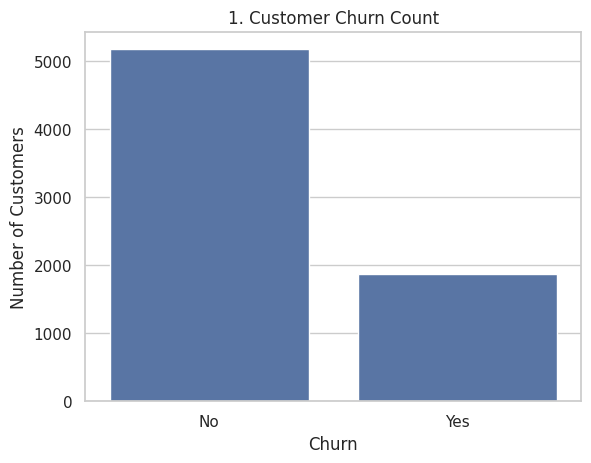

In [18]:
sns.countplot(data=df, x="Churn")
plt.title("1. Customer Churn Count")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

Insight: Shows how many customers left versus stayed. This reveals whether the target is imbalanced.

### **Churn percentage**

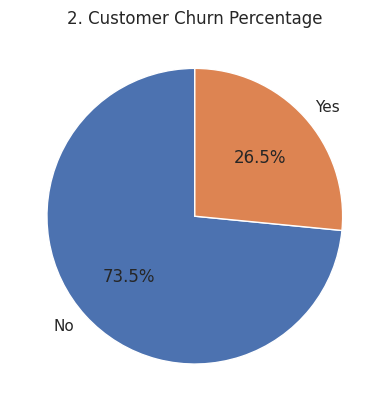

In [19]:
df["Churn"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)
plt.title("2. Customer Churn Percentage")
plt.ylabel("")
plt.show()

Insight: Communicates the proportion of churned and retained customers. In this dataset, churn is the minority class, so accuracy alone will not be enough to evaluate a model.

### **Churn by gender**

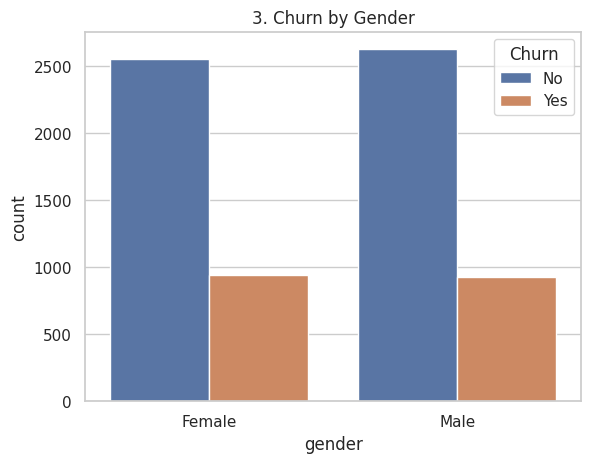

In [20]:
sns.countplot(data=df, x="gender", hue="Churn")
plt.title("3. Churn by Gender")
plt.show()

Insight: Compares churn counts across gender categories. Compare proportions as well as counts because the category sizes may differ.

### **Churn by senior-citizen status**

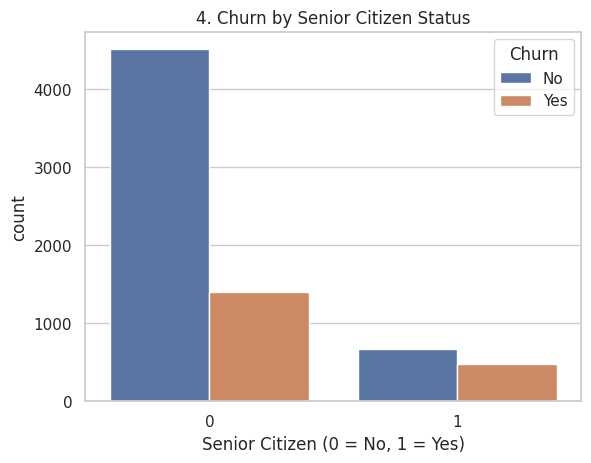

In [21]:
sns.countplot(data=df, x="SeniorCitizen", hue="Churn")
plt.title("4. Churn by Senior Citizen Status")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.show()

Insight: Examines whether churn patterns differ for senior and non-senior customers.

### **Churn by partner status**

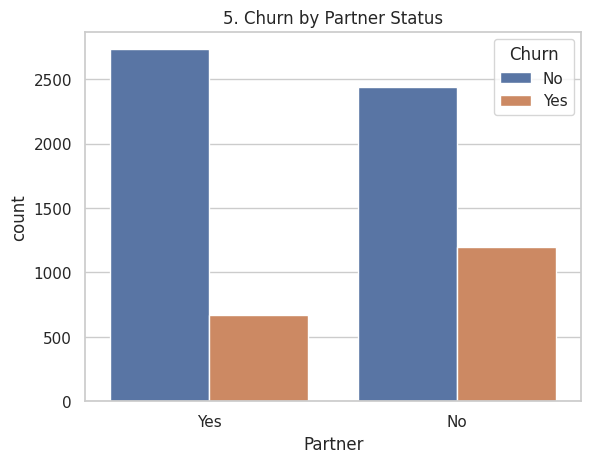

In [22]:
sns.countplot(data=df, x="Partner", hue="Churn")
plt.title("5. Churn by Partner Status")
plt.show()

### **Churn by dependents**

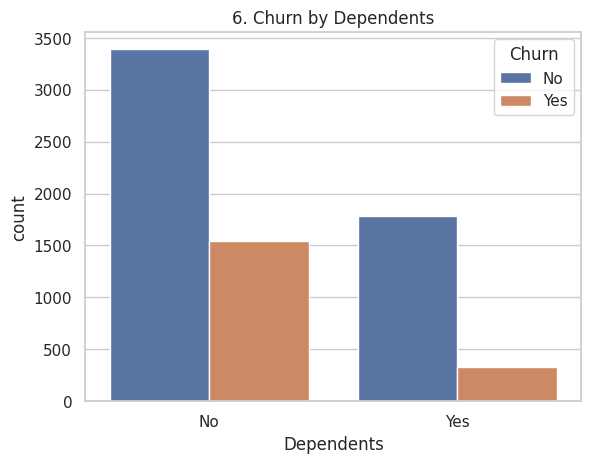

In [23]:
sns.countplot(data=df, x="Dependents", hue="Churn")
plt.title("6. Churn by Dependents")
plt.show()

Insight: Compares customer churn across dependent-status categories.

### **Customer tenure distribution**

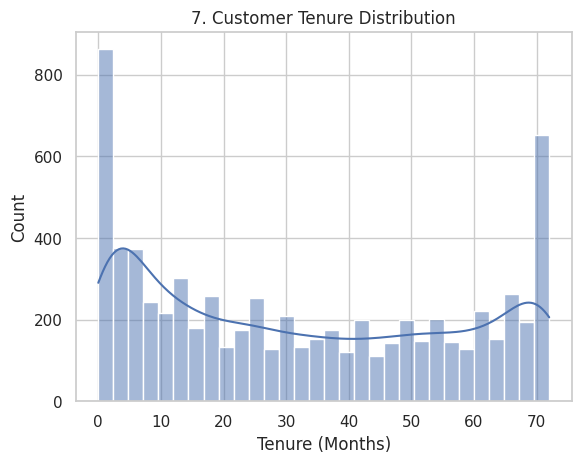

In [24]:
sns.histplot(data=df, x="tenure", bins=30, kde=True)
plt.title("7. Customer Tenure Distribution")
plt.xlabel("Tenure (Months)")
plt.show()

Insight: Shows whether the customer base consists mainly of new customers, long-term customers, or a mixture of both.

### **Tenure by churn**

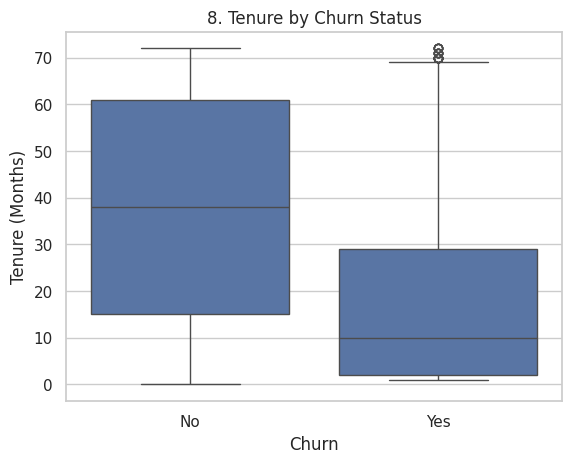

In [25]:
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("8. Tenure by Churn Status")
plt.ylabel("Tenure (Months)")
plt.show()

Insight: Compares the median tenure and spread between churned and retained customers. A lower tenure among churned customers would suggest that early customer retention deserves attention.

## **Monthly-charge distribution**

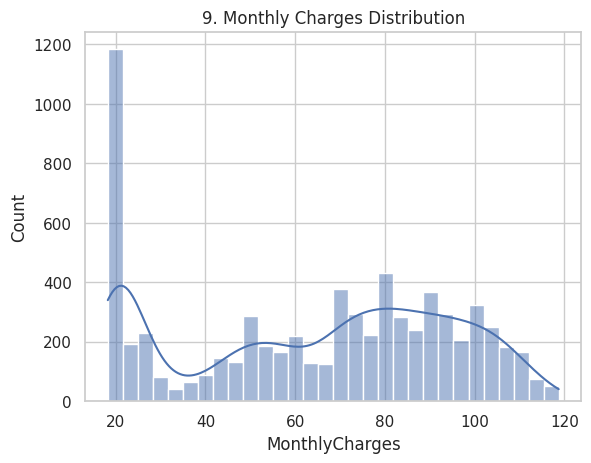

In [26]:
sns.histplot(data=df, x="MonthlyCharges", bins=30, kde=True)
plt.title("9. Monthly Charges Distribution")
plt.show()

Insight: Shows the distribution of monthly charges and whether the customer base is concentrated in particular price ranges.

### **Monthly charges by churn**

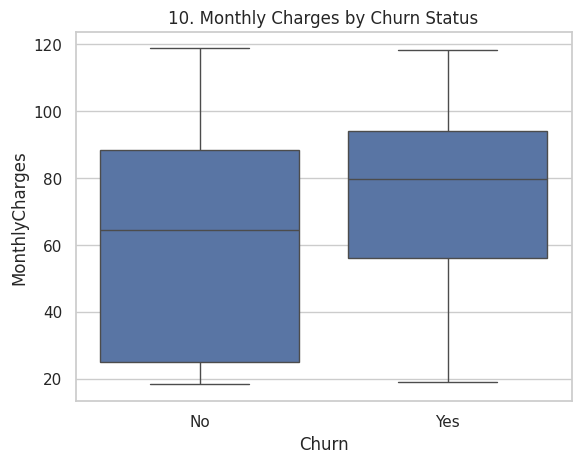

In [27]:
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("10. Monthly Charges by Churn Status")
plt.show()

Insight: Tests whether monthly billing levels differ between churned and retained customers.

### **Total-charge distribution**

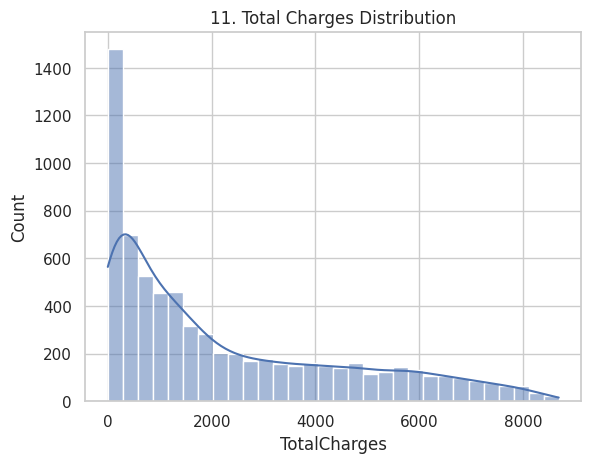

In [28]:
sns.histplot(data=df, x="TotalCharges", bins=30, kde=True)
plt.title("11. Total Charges Distribution")
plt.show()

Insight: Shows accumulated customer spending. Total charges are influenced by both monthly charges and tenure, so interpret this graph in conjunction with those variables.

### **Total charges by churn**

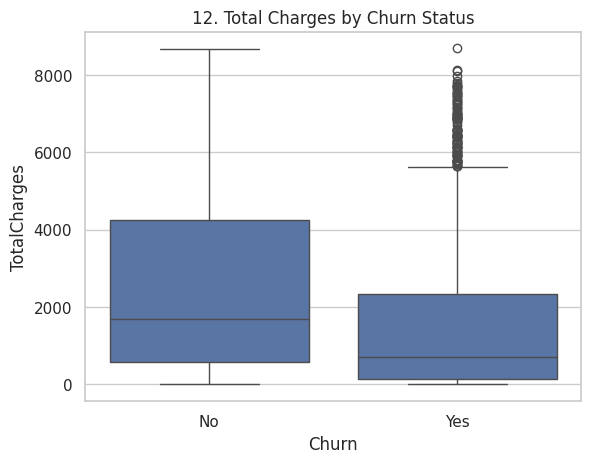

In [29]:
sns.boxplot(data=df, x="Churn", y="TotalCharges")
plt.title("12. Total Charges by Churn Status")
plt.show()

Insight: Compares accumulated charges between customer groups. Lower total charges among churned customers may reflect shorter customer tenure rather than lower monthly prices.

### **Churn rate by contract type**

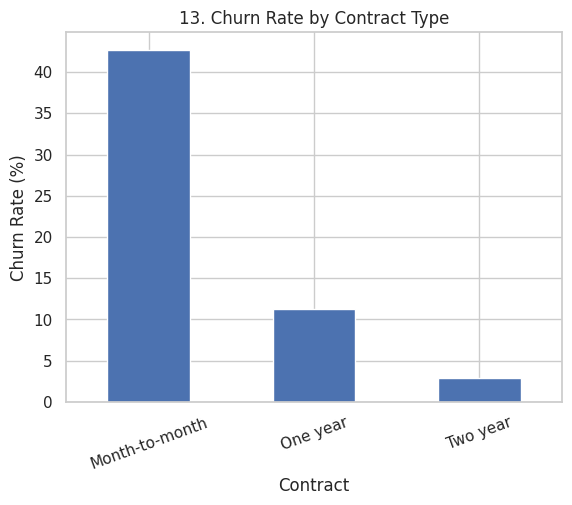

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: ChurnFlag, dtype: float64


In [30]:
contract_rate = (
    df.groupby("Contract", observed=True)["ChurnFlag"]
    .mean()
    .sort_values(ascending=False) * 100
)

contract_rate.plot(kind="bar")
plt.title("13. Churn Rate by Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20)
plt.show()

print(contract_rate.round(2))

Insight: Identifies contract categories with the highest churn rates. This is one of the most important analyses for retention strategy.

### **Churn rate by payment method**

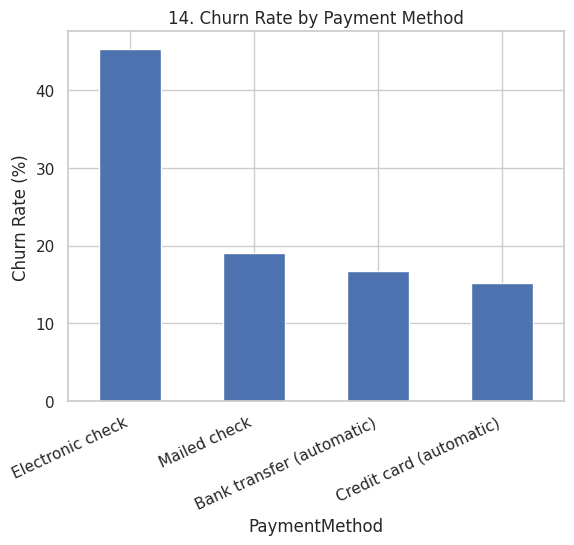

PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: ChurnFlag, dtype: float64


In [31]:
payment_rate = (
    df.groupby("PaymentMethod")["ChurnFlag"]
    .mean()
    .sort_values(ascending=False) * 100
)

payment_rate.plot(kind="bar")
plt.title("14. Churn Rate by Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=25, ha="right")
plt.show()

print(payment_rate.round(2))

Insight: Identifies payment-method groups with different churn rates. The relationship may reflect differences in customer tenure, contract type, or billing preferences rather than a causal effect of payment method.

### **Churn rate by internet service**

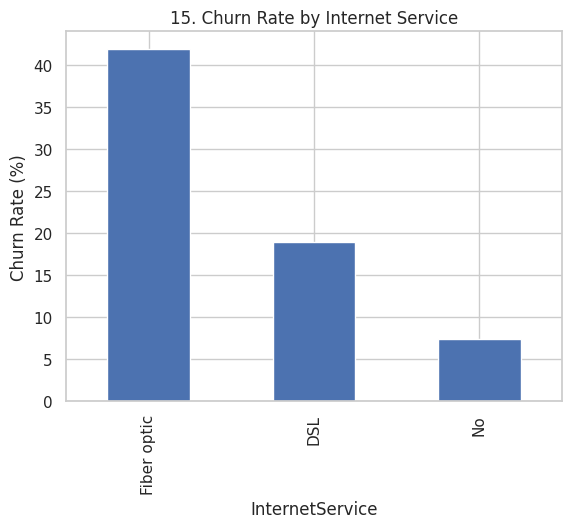

InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: ChurnFlag, dtype: float64


In [32]:
internet_rate = (
    df.groupby("InternetService")["ChurnFlag"]
    .mean()
    .sort_values(ascending=False) * 100
)

internet_rate.plot(kind="bar")
plt.title("15. Churn Rate by Internet Service")
plt.ylabel("Churn Rate (%)")
plt.show()

print(internet_rate.round(2))

Insight: Compares churn rates across internet-service categories and helps identify which customer segments need further investigation.

### **Churn rate by online security**

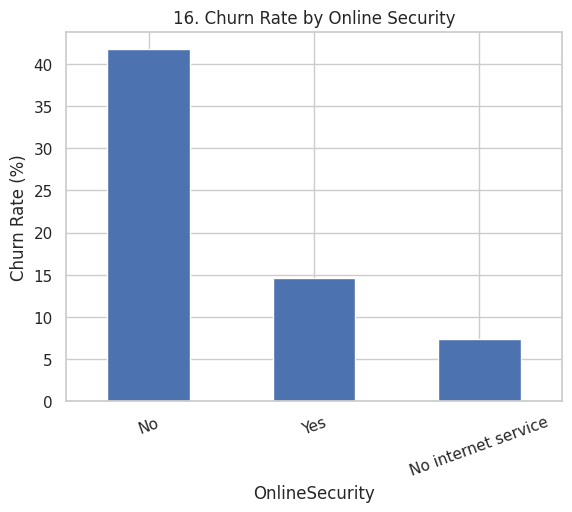

In [33]:
security_rate = (
    df.groupby("OnlineSecurity")["ChurnFlag"]
    .mean()
    .sort_values(ascending=False) * 100
)

security_rate.plot(kind="bar")
plt.title("16. Churn Rate by Online Security")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20)
plt.show()

Insight: Tests whether online-security subscription categories are associated with retention.

### **Churn rate by technical support**

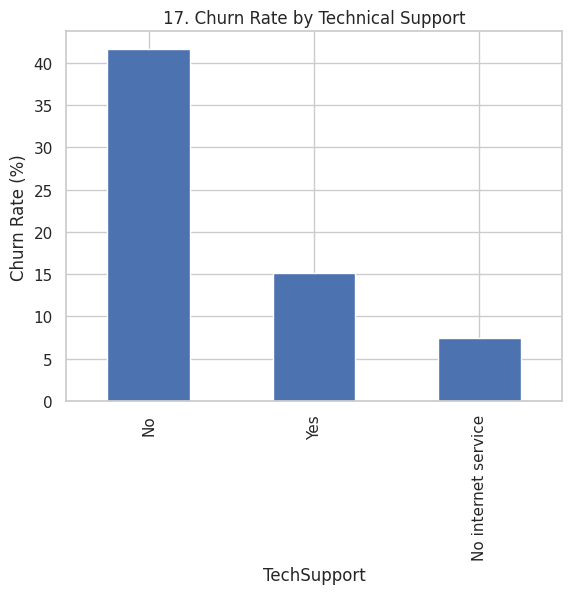

In [34]:
support_rate = (
    df.groupby("TechSupport")["ChurnFlag"]
    .mean()
    .sort_values(ascending=False) * 100
)

support_rate.plot(kind="bar")
plt.title("17. Churn Rate by Technical Support")
plt.ylabel("Churn Rate (%)")
plt.show()

Insight: Helps investigate whether technical-support subscription status is associated with churn. This does not measure actual customer satisfaction or support quality.

### **Churn by paperless billing**

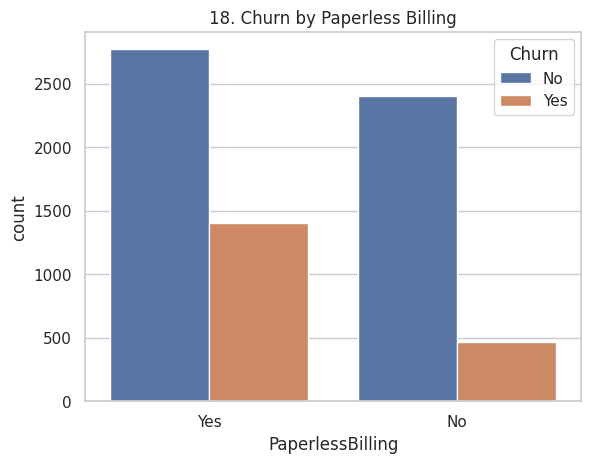

In [35]:
sns.countplot(data=df, x="PaperlessBilling", hue="Churn")
plt.title("18. Churn by Paperless Billing")
plt.show()

Insight: Compares churn counts for paperless-billing customers and customers who receive paper bills.

### **Churn by phone service**

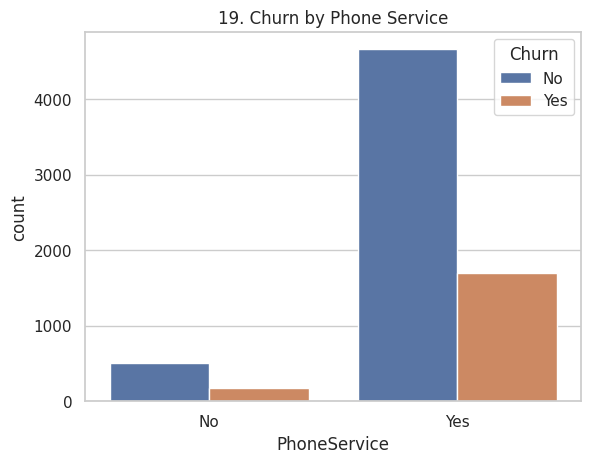

In [36]:
sns.countplot(data=df, x="PhoneService", hue="Churn")
plt.title("19. Churn by Phone Service")
plt.show()

Insight: Compares churn counts by phone-service subscription. Consider category size before drawing conclusions.

### **Churn by multiple lines**

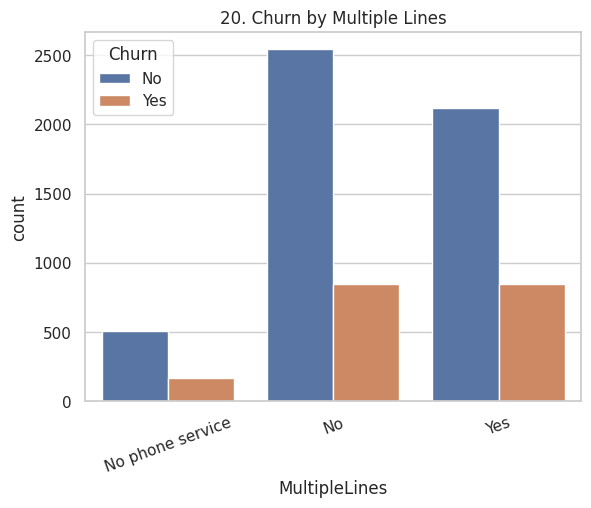

In [37]:
sns.countplot(data=df, x="MultipleLines", hue="Churn")
plt.title("20. Churn by Multiple Lines")
plt.xticks(rotation=20)
plt.show()

Insight: Compares churn patterns for customers with different multiple-line subscription categories.

### **Churn by online backup**

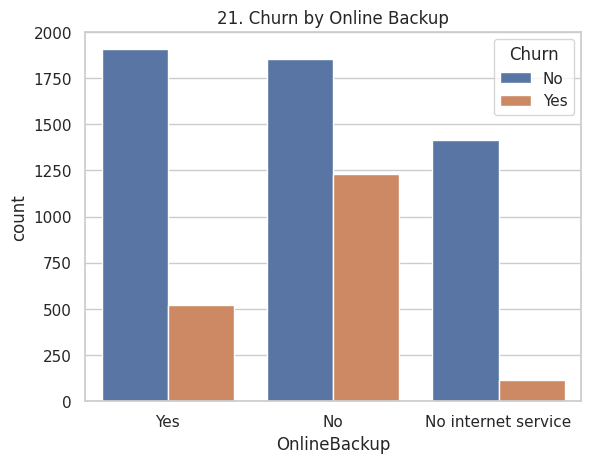

In [38]:
sns.countplot(data=df, x="OnlineBackup", hue="Churn")
plt.title("21. Churn by Online Backup")
plt.show()

Insight: Examines whether online-backup subscription status is associated with customer retention.

### **Churn by device protection**

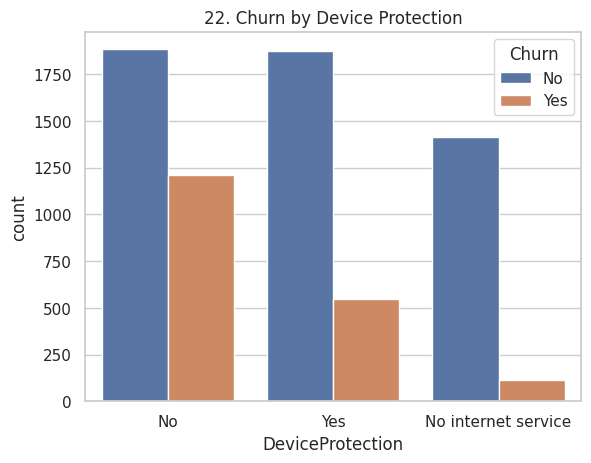

In [39]:
sns.countplot(data=df, x="DeviceProtection", hue="Churn")
plt.title("22. Churn by Device Protection")
plt.show()

Insight: Compares churn counts between device-protection subscription categories.

## **Churn by streaming TV**

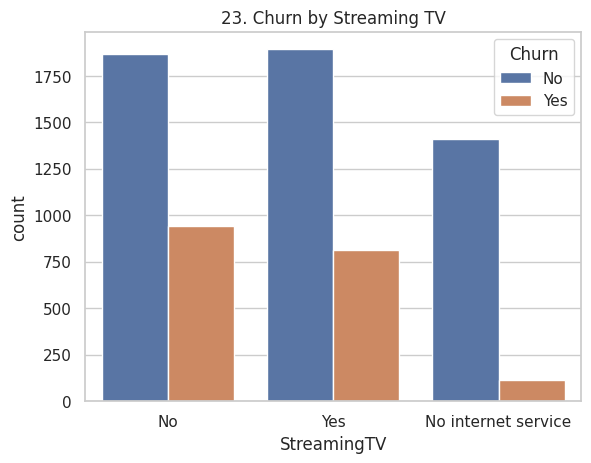

In [40]:
sns.countplot(data=df, x="StreamingTV", hue="Churn")
plt.title("23. Churn by Streaming TV")
plt.show()

Insight: Examines the relationship between streaming-TV subscriptions and churn.

### **Churn by streaming movies**

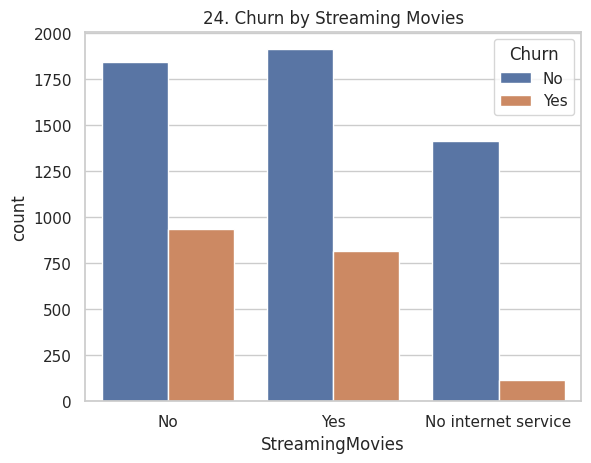

In [41]:
sns.countplot(data=df, x="StreamingMovies", hue="Churn")
plt.title("24. Churn by Streaming Movies")
plt.show()

Insight: Compares customer churn across streaming-movie subscription categories.

### **Correlation heatmap**

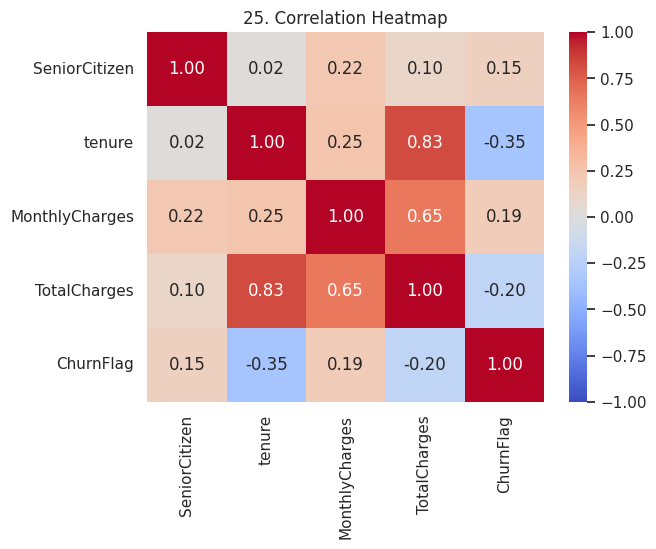

In [42]:
numeric_cols = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "ChurnFlag"
]

correlation = df[numeric_cols].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("25. Correlation Heatmap")
plt.show()

Insight: Displays linear correlation between numerical variables and the binary churn indicator. Correlation does not prove causation and may miss nonlinear relationships.

### **Churn rate by tenure group**

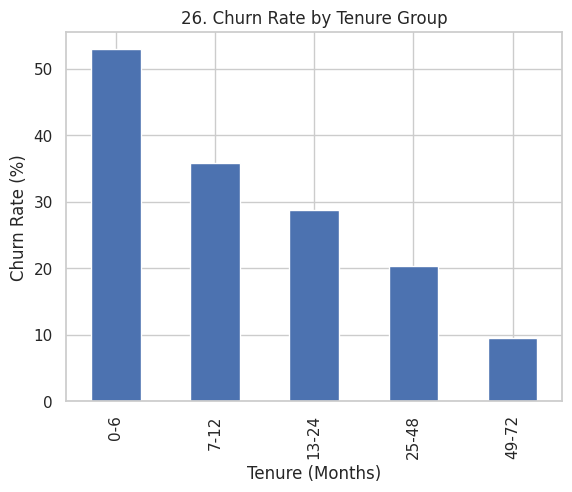

TenureGroup
0-6      52.94
7-12     35.89
13-24    28.71
25-48    20.39
49-72     9.51
Name: ChurnFlag, dtype: float64


In [43]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=["0-6", "7-12", "13-24", "25-48", "49-72"]
)

tenure_rate = (
    df.groupby("TenureGroup", observed=False)["ChurnFlag"]
    .mean() * 100
)

tenure_rate.plot(kind="bar")
plt.title("26. Churn Rate by Tenure Group")
plt.xlabel("Tenure (Months)")
plt.ylabel("Churn Rate (%)")
plt.show()

print(tenure_rate.round(2))

Insight: Shows which customer-lifecycle stages have the highest churn rates. These groups can guide the timing of retention campaigns.

### **Tenure versus monthly charges**

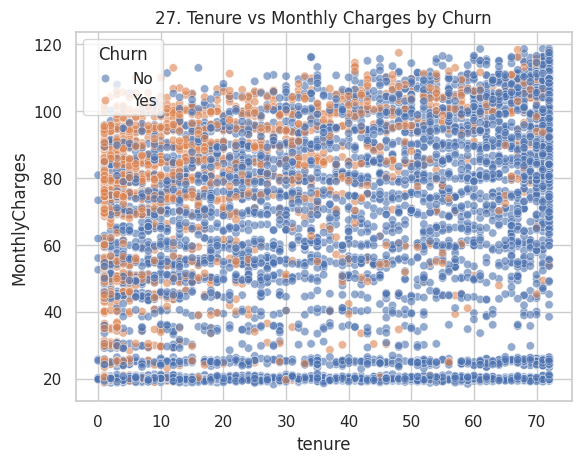

In [44]:
sns.scatterplot(
    data=df,
    x="tenure",
    y="MonthlyCharges",
    hue="Churn",
    alpha=0.6
)

plt.title("27. Tenure vs Monthly Charges by Churn")
plt.show()

Insight: Shows how tenure and monthly charges interact across churn categories. It can reveal patterns that individual histograms do not show.

# **Data preprocessing**
Data preprocessing prepares the dataset for machine learning. The goal is to make every input feature usable by the algorithms while avoiding data leakage.

In [45]:
# Target: what we want to predict
y = df["Churn"].map({"No": 0, "Yes": 1})

# Remove the target, customer identifier, and EDA-only columns
X = df.drop(
    columns=["Churn", "customerID", "ChurnFlag", "TenureGroup"]
)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


X contains the information used to predict churn, while y contains the correct answer. We remove the customer ID and EDA helper columns to prevent leakage.

# **Identify numerical and categorical columns**

In [46]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


Insight: Numerical data and categorical data need different transformations.
- Numerical features can be scaled.
- Categorical features need to be converted into numerical representations.

# **Create a preprocessing pipeline**

In [47]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Process numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Process categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


# **Feature engineering and feature selection**
Feature engineering means creating or transforming features to represent business concepts. Feature selection means deciding which inputs should be used for prediction.

Existing useful features
The dataset already contains several meaningful features:
- tenure: customer lifecycle stage
- MonthlyCharges: recurring revenue exposure
- TotalCharges: accumulated customer spending
- Contract: commitment duration
- InternetService: service category
- TechSupport: technical-support subscription
- PaymentMethod: payment category

We will exclude:
- customerID: identifier, not a meaningful predictor.
- Churn: target variable.
- ChurnFlag and TenureGroup: temporary EDA variables.

# **Split the dataset**

We will use an 80:20 train/test split.
- Training set: 80% of the data, used to learn and tune the model.
- Test set: 20% of the data, held aside for final evaluation.

In [48]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining churn rate:", round(y_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")

Training features: (5634, 19)
Testing features: (1409, 19)

Training churn rate: 26.54 %
Testing churn rate: 26.54 %


Why use stratify=y?


Churn is the minority class. Stratification preserves approximately the same proportion of churned and retained customers in both sets.

Why use random_state=42?


It makes the split reproducible, so you can rerun the notebook and obtain the same split.



Critical rule: Do not use the test set for feature selection, hyperparameter tuning, or repeatedly changing the model. We will reserve it for the final evaluation.

# **Model selection**

1. Logistic Regression

A classification algorithm that estimates churn probability. It provides a strong, interpretable baseline and is often effective for structured data.

2. Random Forest

Combines multiple decision trees. It can capture nonlinear relationships and interactions among customer characteristics.

3. Gradient Boosting

Builds trees sequentially to improve on earlier errors. It is useful for structured tabular datasets and can capture more complex patterns.

We will use ROC-AUC for initial model comparison because it measures how well a model ranks churned customers above retained customers across different classification thresholds.

In [49]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

print("Models ready for comparison.")

Models ready for comparison.


Why use class_weight="balanced" for logistic regression and random forest?

-> It gives greater weight to the minority class during training, which may improve churn detection. It does not guarantee better performance; we will evaluate the results.

# **Train and compare the models**

We will use five-fold stratified cross-validation on the training data. Each model is trained and evaluated across five folds, allowing us to compare performance more reliably than using one validation split.

In [50]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Mean ROC-AUC": scores.mean(),
        "Std ROC-AUC": scores.std()
    })

results_df = pd.DataFrame(results).sort_values(
    by="Mean ROC-AUC",
    ascending=False
)

display(results_df.round(4))

,Model,Mean ROC-AUC,Std ROC-AUC
2,Gradient Boosting,0.8481,0.0126
0,Logistic Regression,0.8460,0.0124
1,Random Forest,0.8206,0.0120


What does this code tell us?

Mean ROC-AUC - Average ability to distinguish churned and retained customers

Standard deviation - How much performance varies across the five folds

Higher mean ROC-AUC - Better ranking performance, on average

Lower standard deviation - More consistent performance across folds

Model-selection rule: Choose the candidate with the strongest cross-validation ROC-AUC, while also considering recall, precision, interpretability, and business cost. A tiny ROC-AUC improvement may not justify a substantially more complex model.

# **Hyperparameter tuning**

Hyperparameters are settings that we choose before model training. Unlike model parameters, they are not learned directly from the training examples.

Examples include:
- Logistic Regression: regularization strength (C)
- Random Forest: number of trees, tree depth, and minimum leaf size
- Gradient Boosting: number of boosting stages, learning rate, and tree depth

# **Configure the search**

We will tune the best-performing model from Step 12 using GridSearchCV.

In [51]:
from sklearn.model_selection import GridSearchCV

best_model_name = results_df.iloc[0]["Model"]
print("Selected model for tuning:", best_model_name)

# Use a smaller, reasonable search space
if best_model_name == "Logistic Regression":

    selected_model = LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )

    param_grid = {
        "model__C": [0.1, 1, 10],
        "model__solver": ["liblinear", "lbfgs"]
    }

elif best_model_name == "Random Forest":

    selected_model = RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    )

    param_grid = {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_leaf": [1, 3]
    }

else:

    selected_model = GradientBoostingClassifier(
        random_state=42
    )

    param_grid = {
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [2, 3]
    }

Selected model for tuning: Gradient Boosting


Why use a limited search grid?

-> It keeps the code understandable and training time manageable. We can expand the search later if the initial results justify it.

# **Run hyperparameter tuning**

In [52]:
tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", selected_model)
])

grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation ROC-AUC:")
print(round(grid_search.best_score_, 4))

best_model = grid_search.best_estimator_

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best parameters:
{'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 200}

Best cross-validation ROC-AUC:
0.8498


How does this work?
1. GridSearchCV tries the specified combinations of hyperparameters.
2. Each combination is evaluated using five-fold cross-validation.
3. The mean ROC-AUC is calculated for each combination.
4. The combination with the highest mean ROC-AUC is selected.
5. The best pipeline is refitted on the training data.

Insight: Compare grid_search.best_score_ with the original model's cross-validation score. A small difference may mean the default model was already competitive. Tuning does not guarantee a large improvement.

# **Model testing and evaluation**

Now we evaluate the tuned model using the test set, which has not been used to select the model or its hyperparameters.

# **Generate predictions**

In [53]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Predicted class
y_pred = best_model.predict(X_test)

# Probability of churn (positive class)
y_prob = best_model.predict_proba(X_test)[:, 1]

print("Predictions generated.")

Predictions generated.


y_pred contains the predicted class labels, while y_prob contains estimated churn probabilities. Probability predictions let us rank customers by estimated churn risk.

# **Calculate evaluation metrics**

In [55]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

display(metrics_df.round(4))

,Metric,Score
0,Accuracy,0.7984
1,Precision,0.6562
2,Recall,0.5053
3,F1 Score,0.5710
4,ROC-AUC,0.8455


# **Confusion matrix**

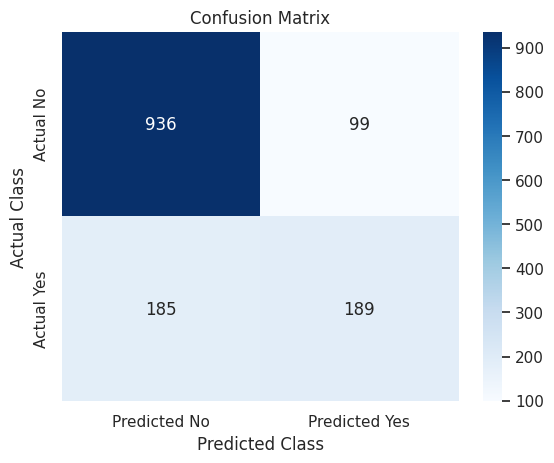

Confusion matrix:
[[936  99]
 [185 189]]


In [56]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted No", "Predicted Yes"],
    yticklabels=["Actual No", "Actual Yes"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

print("Confusion matrix:")
print(cm)

True positive: A customer who churned and was correctly identified.



False negative: A customer who churned but was missed.



False positive: A customer who was flagged as at risk but did not churn.



True negative: A customer who stayed and was correctly identified.

# **Classification report**

In [57]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Churned"],
    zero_division=0
))

              precision    recall  f1-score   support

      Stayed       0.83      0.90      0.87      1035
     Churned       0.66      0.51      0.57       374

    accuracy                           0.80      1409
   macro avg       0.75      0.70      0.72      1409
weighted avg       0.79      0.80      0.79      1409



Insight: This displays precision, recall, and F1 for both classes. Always inspect the Churned row separately; overall accuracy can hide weak performance on the minority class.

# **ROC curve**

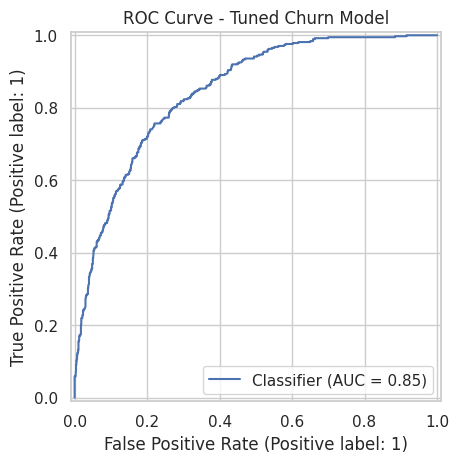

In [58]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_test, y_prob)

plt.title("ROC Curve - Tuned Churn Model")
plt.show()

Insight: The ROC curve shows the trade-off between the true-positive rate and false-positive rate at different thresholds. A curve closer to the top-left generally indicates stronger discrimination.

# **Precision-recall curve**

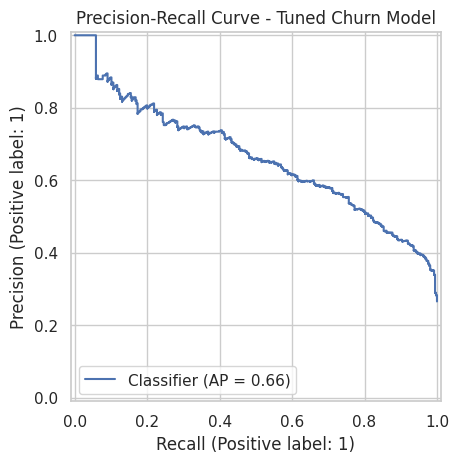

In [59]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(y_test, y_prob)

plt.title("Precision-Recall Curve - Tuned Churn Model")
plt.show()

Insight: This is especially useful when churn is the minority class. It shows how precision changes as we try to capture more churners.

# **Compare the tuned model with the default model**

In [61]:
default_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", models[best_model_name])
])

default_pipeline.fit(X_train, y_train)

default_auc = roc_auc_score(
    y_test,
    default_pipeline.predict_proba(X_test)[:, 1]
)

tuned_auc = roc_auc_score(y_test, y_prob)

print("Default model test ROC-AUC:", round(default_auc, 4))
print("Tuned model test ROC-AUC:", round(tuned_auc, 4))
print("Change in test ROC-AUC:", round(tuned_auc - default_auc, 4))

Default model test ROC-AUC: 0.8434
Tuned model test ROC-AUC: 0.8455
Change in test ROC-AUC: 0.0021


This is a secondary comparison of the default and tuned versions of the same model on the held-out test set. We should interpret it alongside the cross-validation results rather than repeatedly changing the model based on test performance.

# **Feature importance and model**

We will extract feature importance from the tuned model. For tree-based models, we use feature importance scores. For logistic regression, we use the absolute values of its coefficients to rank features by the magnitude of their linear effects.

# **Extract the most important features**

In [62]:
# Get the trained model and transformed feature names
trained_model = best_model.named_steps["model"]

feature_names = (
    best_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Calculate importance according to the model type
if hasattr(trained_model, "feature_importances_"):

    importance_values = trained_model.feature_importances_

else:

    importance_values = np.abs(
        trained_model.coef_[0]
    )

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15).round(4))

,Feature,Importance
36,cat__Contract_Month-to-month,0.3556
1,num__tenure,0.1777
16,cat__InternetService_Fiber optic,0.1273
18,cat__OnlineSecurity_No,0.0797
27,cat__TechSupport_No,0.0591
43,cat__PaymentMethod_Electronic check,0.0551
3,num__TotalCharges,0.0422
2,num__MonthlyCharges,0.0407
12,cat__MultipleLines_No,0.0103
38,cat__Contract_Two year,0.0095


# **Visualize the top 15 features**

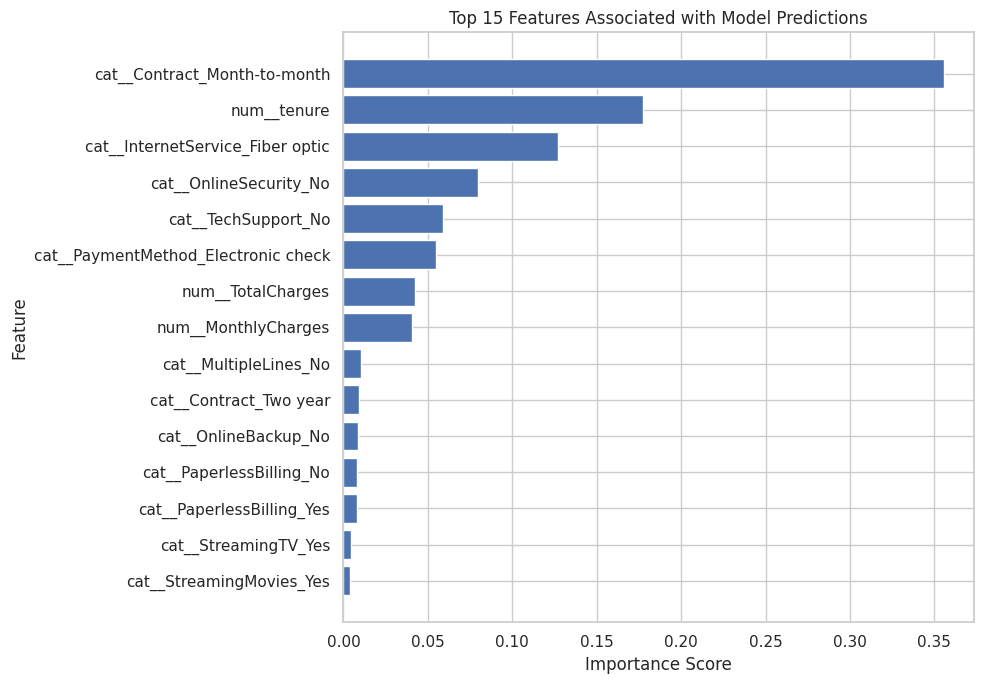

In [63]:
top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Features Associated with Model Predictions")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# **Customer-risk prediction and business validation**

The business needs a usable output, not only an evaluation score. We will create a report that assigns a churn probability to each test-set customer.

# **Create a customer-risk report**

In [70]:
risk_report = X_test.copy()

# Add customer ID for business reporting only
risk_report.insert(
    0,
    "customerID",
    df.loc[X_test.index, "customerID"]
)

risk_report["Actual_Churn"] = y_test
risk_report["Predicted_Churn"] = y_pred
risk_report["Churn_Probability"] = y_prob

risk_report["Risk_Level"] = pd.cut(
    risk_report["Churn_Probability"],
    bins=[-0.001, 0.30, 0.60, 1.00],
    labels=["Low", "Medium", "High"]
)

risk_report = risk_report.sort_values(
    by="Churn_Probability",
    ascending=False
)

display(
    risk_report[
        [
            "customerID",
            "Churn_Probability",
            "Risk_Level",
            "Actual_Churn",
            "Predicted_Churn"
        ]
    ].head(20)
)

,customerID,Churn_Probability,Risk_Level,Actual_Churn,Predicted_Churn
3380,5178-LMXOP,0.908626,High,1,1
6866,0295-PPHDO,0.895424,High,1,1
4585,1069-XAIEM,0.885507,High,1,1
2246,7181-BQYBV,0.873555,High,1,1
2797,6023-YEBUP,0.866413,High,1,1
6365,8884-ADFVN,0.863073,High,1,1
2631,6861-XWTWQ,0.863073,High,1,1
642,0970-ETWGE,0.862824,High,1,1
6748,6230-BSUXY,0.862562,High,1,1
6623,9248-OJYKK,0.853367,High,1,1


The probability cutoffs are illustrative business segments, not validated optimal thresholds. You can change them later based on campaign capacity and the cost of missed churners.

What does this report provide?

Actual_Churn - Actual outcome in the held-out test data

Predicted_Churn -	Predicted class using the model's default 0.5 threshold

Churn_Probability	- Estimated probability of churn

Risk_Level -	Illustrative segment based on probability bands

# **Export the report**

In [71]:
risk_report.to_csv(
    "customer_churn_risk_report.csv",
    index=False
)

print("Risk report saved successfully.")

Risk report saved successfully.


In [67]:
from google.colab import files

files.download("customer_churn_risk_report.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Model validation and reliability**

**Review cross-validation stability**

In [68]:
print("Selected model:", best_model_name)

print("Best cross-validation ROC-AUC:",
      round(grid_search.best_score_, 4))

print("Final test ROC-AUC:",
      round(roc_auc, 4))

print("Final test recall:",
      round(recall, 4))

print("Final test precision:",
      round(precision, 4))

Selected model: Gradient Boosting
Best cross-validation ROC-AUC: 0.8498
Final test ROC-AUC: 0.8455
Final test recall: 0.5053
Final test precision: 0.6562


# **Churn-Retention Action Plan**

Priority 1: High Predicted Churn Probability — Prioritize customers with a high predicted probability of churn for targeted retention outreach. The KPI is the retention rate among contacted customers.

Priority 2: Customers in Early Tenure — Improve the onboarding process and proactively check customers’ service experiences to build satisfaction and loyalty. The KPI is the 90-day retention rate.

Priority 3: Customers on Month-to-Month Contracts — Test suitable longer-term plans, discounts, or loyalty benefits to encourage customers to commit to longer contracts. The KPI is the contract conversion rate.

Priority 4: Customers with High Monthly Charges — Review price perception, plan suitability, and available alternatives to ensure customers receive appropriate value for their spending. The KPI is the retention rate by monthly charge band.

Priority 5: Customers with Service or Support Concerns — Investigate customer support needs, resolve service issues, and provide relevant assistance to improve customer satisfaction. The KPIs are repeat complaints and churn rate.

Priority 6: Customers Identified by Payment-Method Patterns — Investigate potential billing difficulties and improve the payment experience where necessary. The KPIs are payment-related complaints and churn rate.

# **summary**

In [69]:
print("=" * 45)
print("CUSTOMER CHURN PREDICTION - FINAL RESULTS")
print("=" * 45)

print("Dataset records:", len(df))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Selected model:", best_model_name)

print("\nBest hyperparameters:")
print(grid_search.best_params_)

print("\nEvaluation results:")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nTop 10 model features:")
display(importance_df.head(10).round(4))

print("\nTop 10 highest-risk test customers:")
display(
    risk_report[
        ["Churn_Probability", "Predicted_Churn", "Risk_Level"]
    ].head(10)
)

CUSTOMER CHURN PREDICTION - FINAL RESULTS
Dataset records: 7043
Training records: 5634
Testing records: 1409
Selected model: Gradient Boosting

Best hyperparameters:
{'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 200}

Evaluation results:
Accuracy:  0.7984
Precision: 0.6562
Recall:    0.5053
F1 Score:  0.5710
ROC-AUC:   0.8455

Top 10 model features:


,Feature,Importance
36,cat__Contract_Month-to-month,0.3556
1,num__tenure,0.1777
16,cat__InternetService_Fiber optic,0.1273
18,cat__OnlineSecurity_No,0.0797
27,cat__TechSupport_No,0.0591
43,cat__PaymentMethod_Electronic check,0.0551
3,num__TotalCharges,0.0422
2,num__MonthlyCharges,0.0407
12,cat__MultipleLines_No,0.0103
38,cat__Contract_Two year,0.0095



Top 10 highest-risk test customers:


,Churn_Probability,Predicted_Churn,Risk_Level
3380,0.908626,1,High
6866,0.895424,1,High
4585,0.885507,1,High
2246,0.873555,1,High
2797,0.866413,1,High
6365,0.863073,1,High
2631,0.863073,1,High
642,0.862824,1,High
6748,0.862562,1,High
6623,0.853367,1,High
